In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [2]:
df = pd.read_csv("/Users/vm/Ironhack/labs/amz_uk_price_prediction_dataset.csv")

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
df.shape

(2443651, 9)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [6]:
list(set(df.dtypes.tolist()))

[dtype('int64'), dtype('O'), dtype('float64'), dtype('bool')]

In [7]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [8]:
df.select_dtypes("number").columns

Index(['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth'], dtype='object')

In [9]:
df.select_dtypes("number").nunique().sort_values(ascending=False)

uid                  2443651
price                  82916
reviews                19446
stars                     42
boughtInLastMonth         25
dtype: int64

In [10]:
df.select_dtypes("object").columns

Index(['asin', 'title', 'category'], dtype='object')

In [11]:
df.select_dtypes("object").nunique().sort_values(ascending=False)

asin        2222742
title       2077591
category        296
dtype: int64

In [12]:
#Generate a frequency table for the product category.
frequency_table = df['category'].value_counts()
frequency_table


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [13]:
frequency_table.head(5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

/var/folders/zc/ljl3_lqn79125zg278rlpwtr0000gn/T/ipykernel_16161/1983367653.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=frequency_table.index, y=frequency_table.values, palette = "Set3");


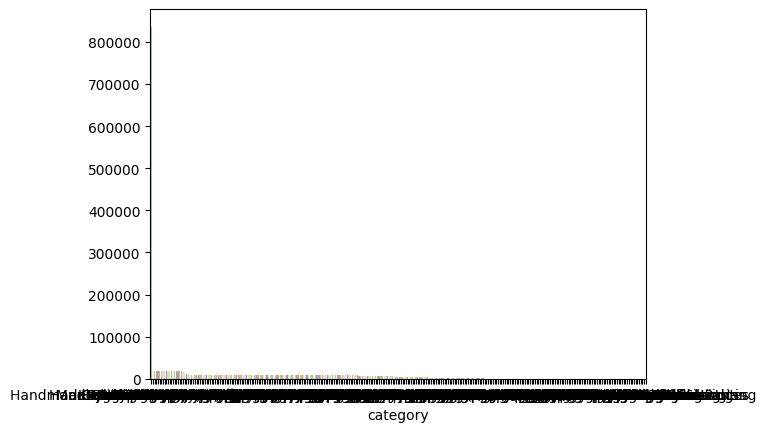

In [14]:
#Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.

sns.barplot(x=frequency_table.index, y=frequency_table.values, palette = "Set3");

/var/folders/zc/ljl3_lqn79125zg278rlpwtr0000gn/T/ipykernel_16161/389259174.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_categories.index, y=top_categories.values, palette = "Set3");


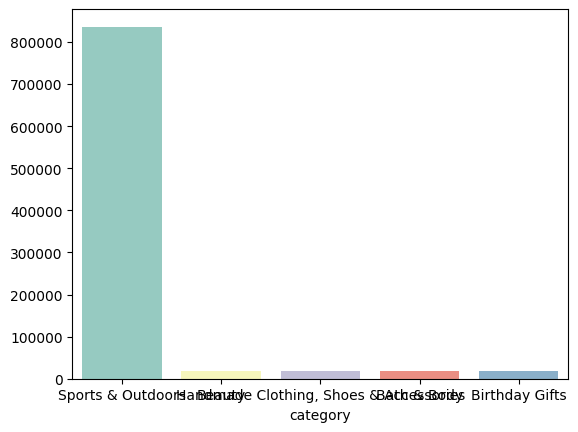

In [15]:
top_categories = frequency_table.sort_values(ascending=False).head(5)
sns.barplot(x=top_categories.index, y=top_categories.values, palette = "Set3");

In [16]:
df.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [17]:
#Calculate the mean, median, and mode for the price of products.
mean_price = df["price"].mean()
median_price = df["price"].median()
mode_price = df["price"].mode()[0]

mean_price, median_price, mode_price

(np.float64(89.24380943923661), np.float64(19.09), np.float64(9.99))

# What's the average price point of products listed? How does this compare with the most common price point (mode)?
89.24 is the average and mode is 9.99.
The mean is much higher than the mode, which shows that few very expensive product are pulling the average up.
The mode is lower than the average, which means that the customers are more like to buy lower priced products.

In [18]:
#Determine the variance, standard deviation, range, and interquartile range for product price.
variance_price = df["price"].var()
std_dev_price = df["price"].std()
max_price = df["price"].max()
min_price = df["price"].min()
range_price = max_price - min_price
quantile_price = df["price"].quantile([0.25, 0.5, 0.75])

variance_price, std_dev_price, max_price, min_price, range_price, quantile_price

(np.float64(119445.48532254901),
 np.float64(345.60886175349873),
 np.float64(100000.0),
 np.float64(0.0),
 np.float64(100000.0),
 0.25     9.99
 0.50    19.09
 0.75    45.99
 Name: price, dtype: float64)

# How varied are the product prices? Are there any indicators of a significant spread in prices?

A lot of variance and it is a wide spread in prices.

<Axes: xlabel='price', ylabel='Count'>

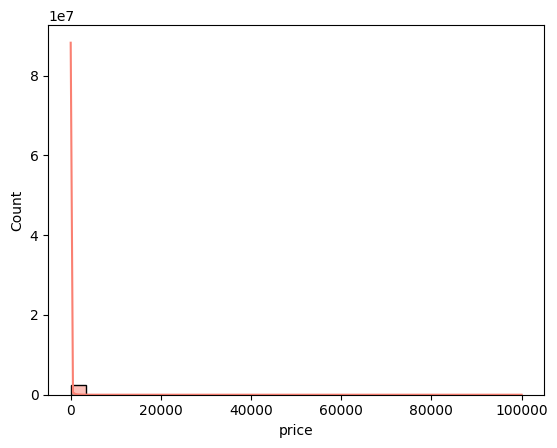

In [19]:
#Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. 
# If its hard to read these diagrams, think why this is, and explain how it could be solved..
sns.histplot(df["price"], kde = True, bins=30, color="salmon")

<Axes: ylabel='price'>

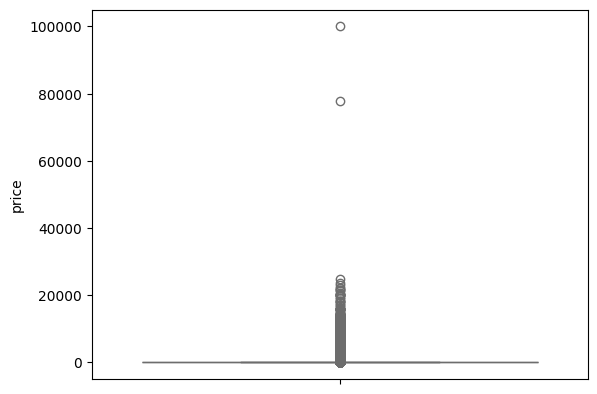

In [20]:
#Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.
sns.boxplot(data = df["price"], color="salmon")

In [21]:
#Calculate the mean, median, and mode for the rating of products.
mean_ratings = df["stars"].mean()
median_ratings = df["stars"].median()
mode_ratings = df["stars"].mode()[0]

mean_ratings, median_ratings, mode_ratings

(np.float64(2.152836472966066), np.float64(0.0), np.float64(0.0))

# How do customers generally rate products? Is there a common trend?

In [22]:
#Determine the variance, standard deviation, and interquartile range for product rating.

variance_rating = df["stars"].var()
std_dev_rating = df["stars"].std()
max_rating = df["stars"].max()
min_rating = df["stars"].min()
range_rating = max_rating - min_rating
quantile_rating = df["stars"].quantile([0.25, 0.5, 0.75])

variance_rating, std_dev_rating, quantile_rating

(np.float64(4.817434029796864),
 np.float64(2.194865378513421),
 0.25    0.0
 0.50    0.0
 0.75    4.4
 Name: stars, dtype: float64)

#Are the ratings consistent, or is there a wide variation in customer feedback?
Ratings are highly inconsistent. Half of customers rated it 0, while the other half gave much higher scores (pulling the mean upward).

In [23]:
skewness_rating = df['stars'].skew()
kurtosis_rating = df['stars'].kurtosis()

skewness_rating, kurtosis_rating

(np.float64(0.08120735761080881), np.float64(-1.9260061280432994))

Are the ratings normally distributed, or do they lean towards higher or lower values?
skewness_rating: Very close to 0, which means the distribution of ratings is almost symmetric. There’s no strong tilt toward low or high ratings overall.
kurtosis_rating: flatter than a normal distribution, with lighter tails.

Ratings are more evenly spread out, with fewer extreme outliers.

<Axes: xlabel='stars', ylabel='Count'>

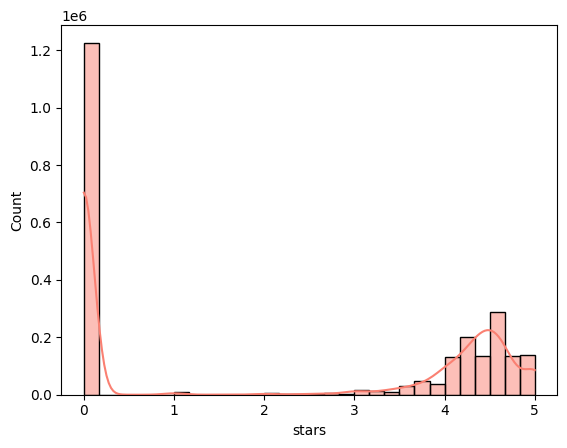

In [ ]:
#Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?
sns.histplot(df['stars'], kde=True, bins=30, color="salmon")

0 is the most common rating